# When spatial aggregation changes a crop–drought report

Choose a state, two USDM valid dates, and the number of spatial crop counts retained per county. The default Kansas example has opposite weekly directions under center-based inclusion and the pixel-center reference. The crop map and county weights stay fixed. Iowa uses 2021 mapped corn with 2022 drought maps. Nebraska and Kansas use 2022 mapped corn with 2023 drought maps.

In [1]:
STATE = 'KS'
BEFORE = '20230829'
AFTER = '20230905'
CELLS = 16
COUNTY = None

In [2]:
from pathlib import Path
import csv
import sys
from datetime import datetime
from IPython.display import Image, Markdown, display

PROJECT = Path.cwd()
if not (PROJECT / 'data').is_dir():
    PROJECT = PROJECT.parent
assert (PROJECT / 'data').is_dir(), 'Open this notebook inside the project folder.'
sys.path.insert(0, str(PROJECT / 'analysis'))
from exhibit import make_exhibit, contributions
from query_summary import query

def read_csv(name):
    with (PROJECT / 'results' / name).open() as stream:
        return list(csv.DictReader(stream))

def direction(value):
    return 'Increase' if value >= 1 else 'Decrease' if value <= -1 else 'Stable'

state_rows = [r for r in read_csv('operator_panel_states.csv') if r['state'] == STATE]
print('Available dates:', ', '.join(r['valid_date'] for r in state_rows))
assert BEFORE < AFTER, 'Choose the earlier date first.'
assert {BEFORE, AFTER} <= {r['valid_date'] for r in state_rows}, 'Select dates from this state panel.'
assert (datetime.strptime(AFTER,'%Y%m%d')-datetime.strptime(BEFORE,'%Y%m%d')).days == 7, 'Choose consecutive weeks, seven days apart.'

Available dates: 20230704, 20230711, 20230718, 20230725, 20230801, 20230808, 20230815, 20230822, 20230829, 20230905, 20230912, 20230919, 20230926


## Compare the report

Each percentage refers to the same prior-season mapped-corn population. The summary query below uses only the county crop counts and drought polygons. The increase/stable/decrease label uses a one-percentage-point threshold. Choose consecutive dates to reproduce a weekly change.

In [3]:
left = next(r for r in state_rows if r['valid_date'] == BEFORE)
right = next(r for r in state_rows if r['valid_date'] == AFTER)
summary_before = query(STATE, BEFORE, CELLS)
summary_after = query(STATE, AFTER, CELLS)
comparison = []
for method, name in [('centroid','County center'), ('internal','Census internal point'), ('area','County area'), ('pixel','Pixel-center reference')]:
    comparison.append((name, float(left[method+'_exposure_pct']), float(right[method+'_exposure_pct'])))
comparison.insert(-1, (f'{CELLS} crop-count cells', summary_before['state_exposure_pct'], summary_after['state_exposure_pct']))
table = '| Calculation | Before (%) | After (%) | Change (pp) | Report |\n|---|---:|---:|---:|---|\n'
for name, before, after in comparison:
    table += f'| {name} | {before:.2f} | {after:.2f} | {after-before:+.2f} | {direction(after-before)} |\n'
display(Markdown(table))

| Calculation | Before (%) | After (%) | Change (pp) | Report |
|---|---:|---:|---:|---|
| County center | 60.99 | 57.95 | -3.04 | Decrease |
| Census internal point | 60.99 | 57.95 | -3.04 | Decrease |
| County area | 57.57 | 59.64 | +2.07 | Increase |
| 16 crop-count cells | 57.63 | 59.54 | +1.91 | Increase |
| Pixel-center reference | 57.38 | 59.35 | +1.97 | Increase |


## Trace the difference to counties

The table ranks counties by their contribution to the difference between center-based and pixel-based changes. The figure shows the two leading counties, their crop pixels, and both drought boundaries. Green shows mapped corn. The shaded sides of the lines show D1+ coverage. Crosses mark geometric county centroids.

| County | Center contribution | Pixel contribution | Difference |
|---|---:|---:|---:|
| Finney | -2.19 | -0.26 | -1.93 |
| Gray | -1.44 | -0.26 | -1.18 |
| Shawnee | +0.00 | +0.40 | -0.40 |
| Neosho | +0.57 | +0.17 | +0.40 |
| Jackson | +0.00 | +0.35 | -0.35 |
| Pottawatomie | +0.00 | +0.33 | -0.33 |
| Nemaha | +0.00 | +0.23 | -0.23 |
| Pratt | +0.00 | +0.15 | -0.15 |

Contributions are in percentage points of the state exposure change.

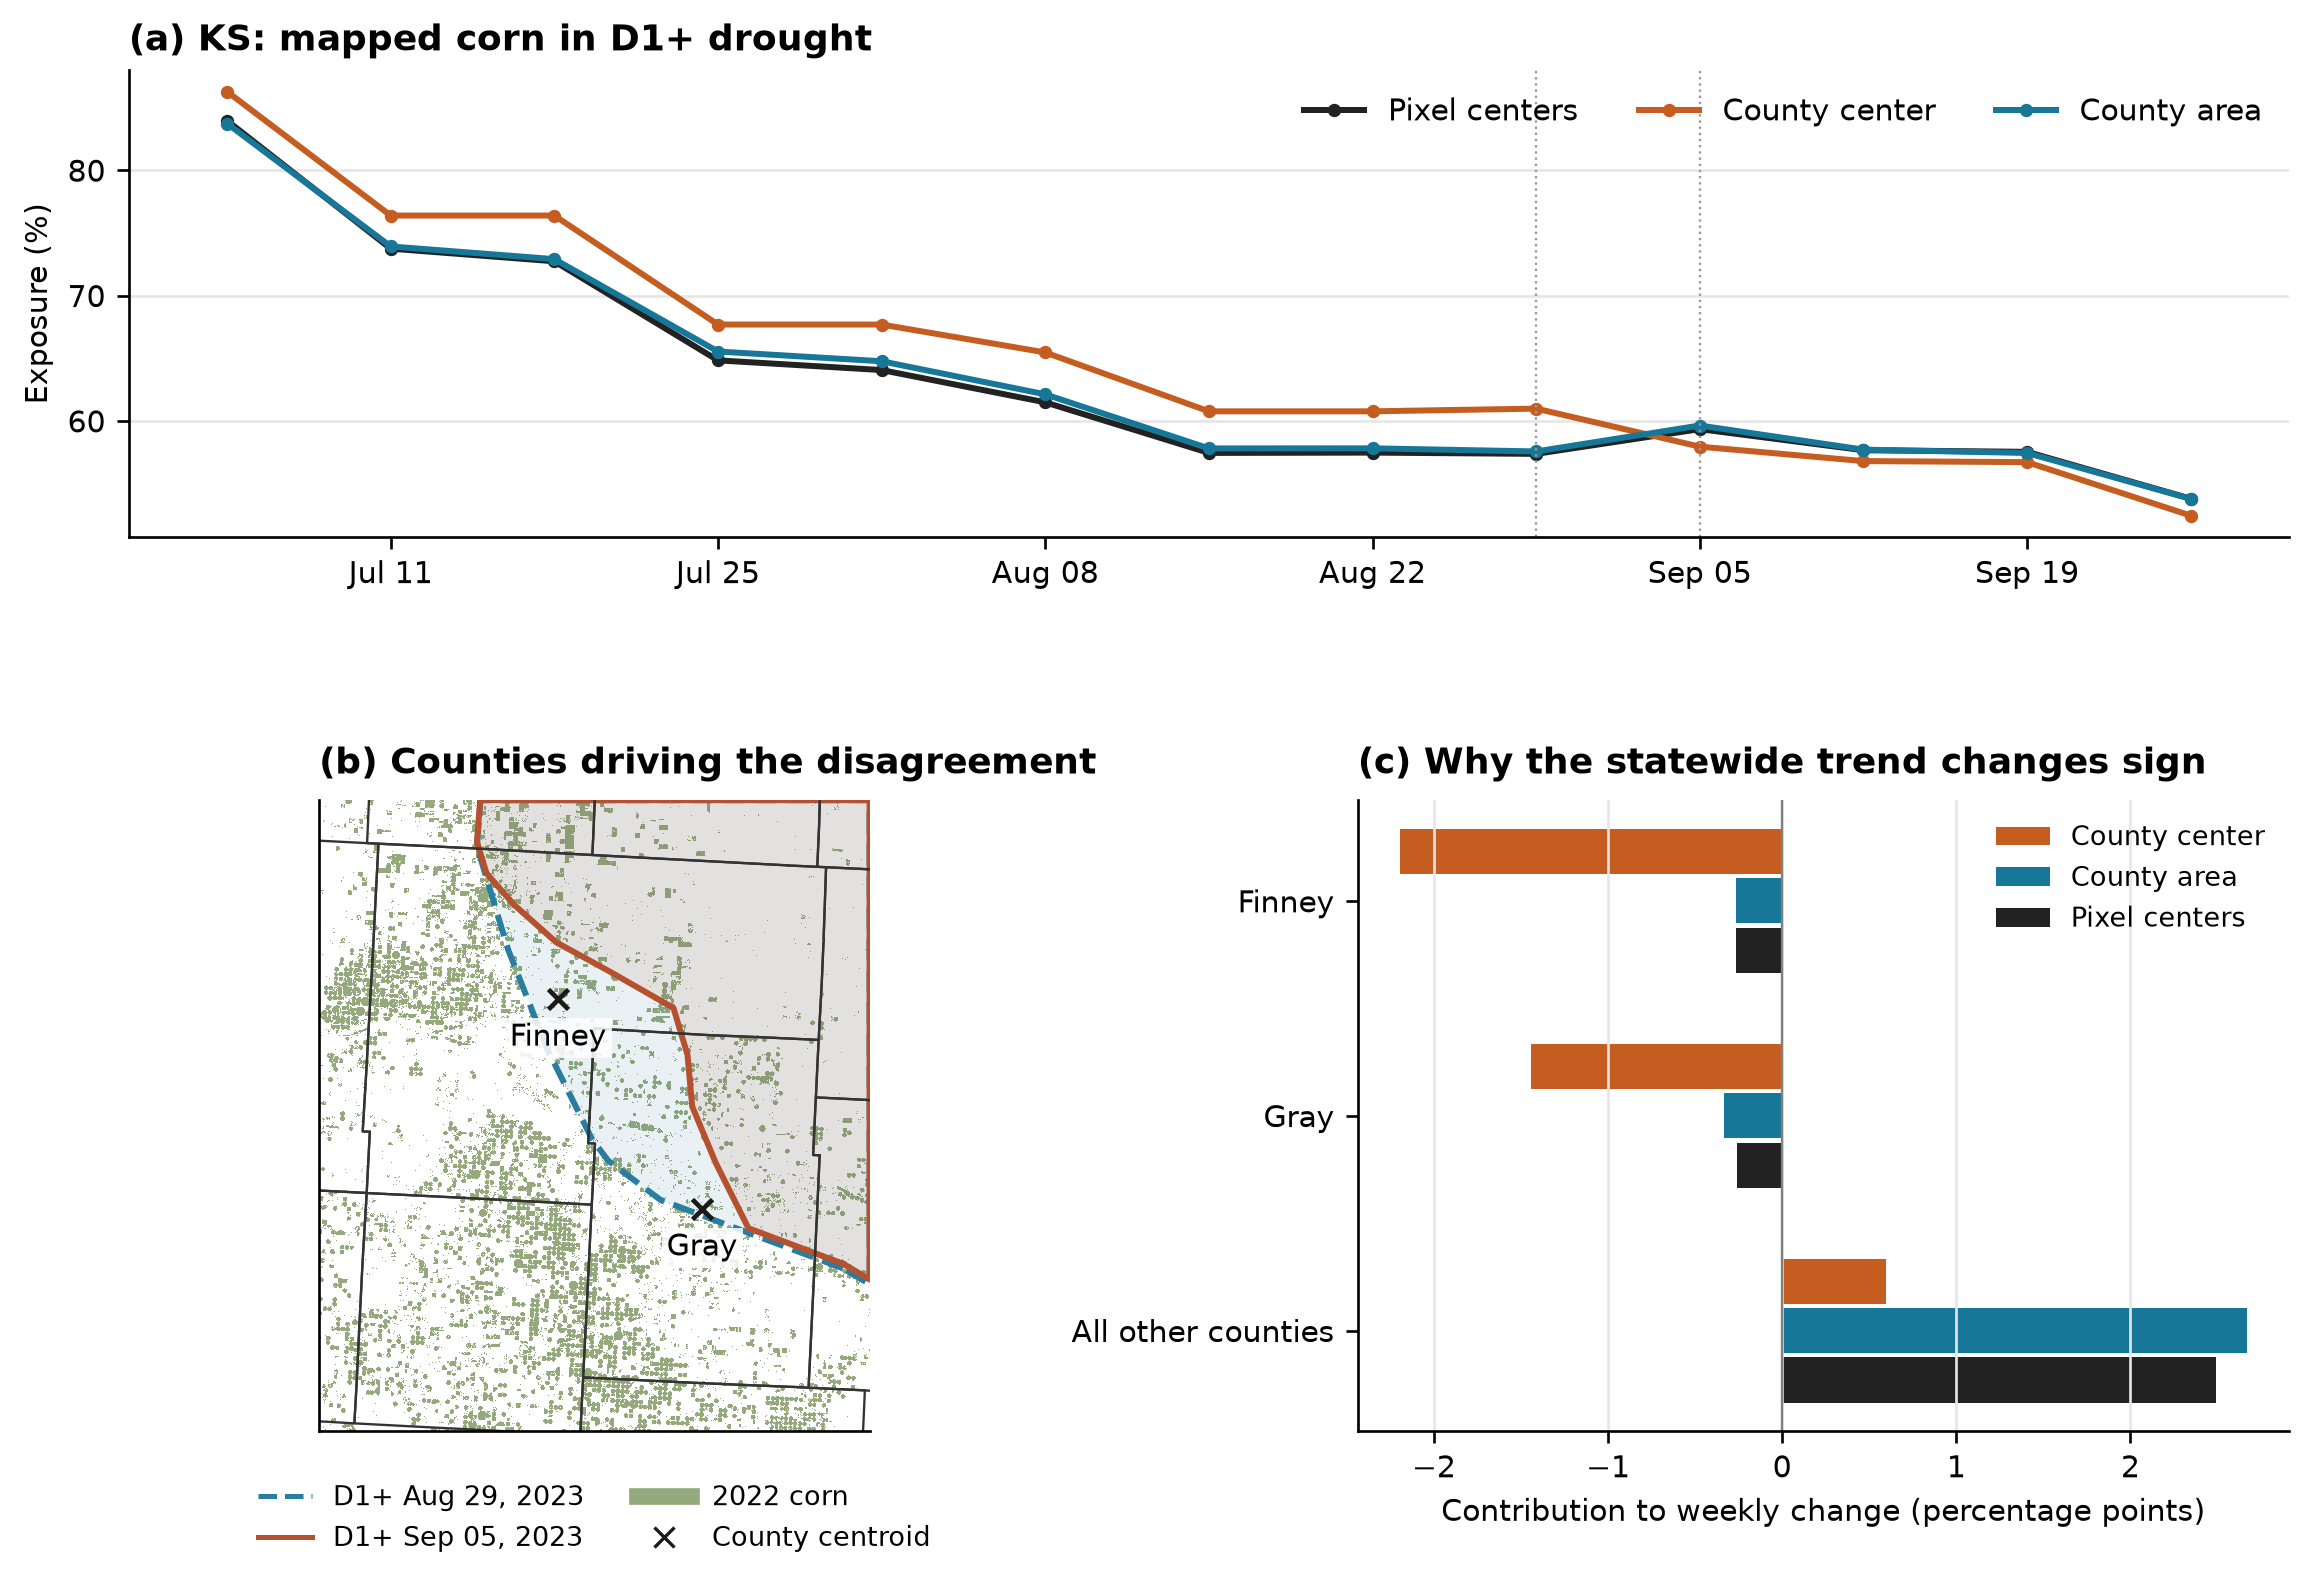

In [4]:
county_changes = contributions(STATE, BEFORE, AFTER)
table = '| County | Center contribution | Pixel contribution | Difference |\n|---|---:|---:|---:|\n'
for row in county_changes[:8]:
    table += f"| {row['county']} | {row['centroid']:+.2f} | {row['pixel']:+.2f} | {row['difference']:+.2f} |\n"
display(Markdown(table+'\nContributions are in percentage points of the state exposure change.'))
figure_stem = PROJECT / 'figures' / f'{STATE}_{BEFORE}_{AFTER}'
make_exhibit(STATE, BEFORE, AFTER, figure_stem)
display(Image(filename=str(figure_stem)+'.png', width=1000))

## Compare local and state errors

A close state total may conceal larger county discrepancies. This cell scores the selected crop-count summary against the pixel-center reference on the later date. Local errors are weighted by each county’s mapped corn population. Change `CELLS` above and rerun to compare one, four, and sixteen counts.

The optional `COUNTY` parameter selects an individual county. Leaving it as `None` chooses the leading center-versus-pixel contributor for the selected state and week.

In [5]:
reference = {r['fips']: r for r in read_csv('operator_panel_counties.csv') if r['state']==STATE and r['valid_date']==AFTER}
counties = summary_after['counties']
population = sum(r['corn_pixels'] for r in counties)
local_error = sum(r['corn_pixels']*abs(100*(r['fraction']-float(reference[r['fips']]['pixel_fraction']))) for r in counties)/population
state_error = abs(summary_after['state_exposure_pct']-float(right['pixel_exposure_pct']))
print(f'{STATE}, {AFTER}, {CELLS} counts per county')
print(f'Corn-weighted mean absolute county error: {local_error:.2f} pp')
print(f'Absolute error of the state total:       {state_error:.2f} pp')
focus = COUNTY or county_changes[0]['county']
selected = next((r for r in counties if r['county']==focus), None)
assert selected is not None, f'{focus} is not a county in {STATE}.'
reference_pct = 100*float(reference[selected['fips']]['pixel_fraction'])
summary_pct = 100*selected['fraction']
print(f'\n{focus} County: pixel exposure {reference_pct:.2f}%, summary {summary_pct:.2f}%')
print(f'County absolute error: {abs(summary_pct-reference_pct):.2f} pp')

KS, 20230905, 16 counts per county
Corn-weighted mean absolute county error: 0.38 pp
Absolute error of the state total:       0.19 pp

Finney County: pixel exposure 14.49%, summary 16.34%
County absolute error: 1.85 pp


## Put the example in the complete panel

All thirteen dates per state are included below. The sixteen-count comparison was designed after the main panel was inspected and is exploratory. The Kansas direction reversal is the only opposite change with both magnitudes at least one point among the 24 Nebraska/Kansas transitions.

In [6]:
main = read_csv('operator_panel_summary.csv')
compact = read_csv('spatial_summary_results.csv')
table = '| State | Center state error | Area state error | Area county error | Sixteen-count county error |\n|---|---:|---:|---:|---:|\n'
for state in ('IA','NE','KS'):
    center = next(r for r in main if r['state']==state and r['method']=='centroid')
    area = next(r for r in compact if r['state']==state and r['method']=='area')
    fine = next(r for r in compact if r['state']==state and r['method']=='histogram_16')
    table += f"| {state} | {float(center['level_mae_pp']):.2f} | {float(area['state_mae_pp']):.2f} | {float(area['county_weighted_mae_pp']):.2f} | {float(fine['county_weighted_mae_pp']):.2f} |\n"
display(Markdown(table+'\nMean absolute errors are in percentage points, averaged over thirteen weeks. County errors are weighted by mapped corn counts.'))

| State | Center state error | Area state error | Area county error | Sixteen-count county error |
|---|---:|---:|---:|---:|
| IA | 1.74 | 0.25 | 0.73 | 0.16 |
| NE | 0.76 | 0.38 | 1.13 | 0.22 |
| KS | 2.60 | 0.30 | 2.40 | 0.43 |

Mean absolute errors are in percentage points, averaged over thirteen weeks. County errors are weighted by mapped corn counts.

The pixel reference is overlap on the selected maps. It inherits their crop labels and drought boundaries. The comparison holds acreage weights fixed and therefore differs from the production-weighted public USDA series. See the project `README.md` for data sources and commands to recompute every result. The scripts use the included data, so the walkthrough needs no network access.